# 1. Librerías

In [3]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import ValidationCurveDisplay, cross_val_predict

import utils.constantes as cte
from utils import modelado as mod

%matplotlib inline

np.random.seed(cte.semilla)

# 2. Train - Test

Datos provenientes de EDA, depurados pero con registros nulos aún, con partición estratificada 80% train, 20% test.

In [4]:
# Misma partición del grupo.
X_train, X_test, y_train, y_test = mod.cargar_datos()

print("Train:", X_train.shape)
print("Proporción de clases:",y_train.value_counts(normalize=True).sort_index().round(2).to_dict())

Train: (1803, 30)
Proporción de clases: {0: 0.5, 1: 0.3, 2: 0.2}


In [5]:
def curva_validacion(busqueda, parametro, valores, titulo):
    """Representa train y validación con media ± desviación, modificando un hiperparámetro."""

    ValidationCurveDisplay.from_estimator(
        busqueda.best_estimator_, X_train,y_train,
        param_name=parametro,
        param_range=valores,
        cv=mod.validador,
        scoring=mod.metrica,
        std_display_style="fill_between",
        n_jobs=-1
    )

    plt.title(titulo)
    plt.ylabel("F1 macro")
    plt.show()

# 3. LDA

* Mínimos cuadrados
* Descomposición de autovalores

In [ ]:
rejilla_lda = [
    #Solver minimos cuadrados, con covarianza regularizada según el ruido
    {"modelo__solver": ["lsqr"],
    "modelo__shrinkage": [None, "auto", 0.1, 0.5, 0.9],},
    #Solver con descomposición de autovalores, con covarianza regularizada según el ruido
    {"modelo__solver": ["eigen"],
    "modelo__shrinkage": [None, "auto", 0.1, 0.5, 0.9],},]

busquedas_lda, tablas_balanceo_lda = {}, []

# LDA no admite class_weight, probamos sin balanceo, SMOTENC y los dos métodos de undersampling
for balanceo in [None, "smotenc", "tomek", "enn"]:
    busqueda = mod.crear_busqueda(mod.crear_pipeline(LinearDiscriminantAnalysis(),balanceo=balanceo), rejilla_lda)
    busquedas_lda[balanceo] = busqueda.fit(X_train,y_train)
    tablas_balanceo_lda.append(mod.tabla_resultados(busqueda,f"lda | {balanceo}"))

balanceo_resultados_lda = pd.concat(tablas_balanceo_lda)
balanceo_resultados_lda[["f1_macro_val", "f1_macro_val_std", "recall_alto_val", "recall_alto_val_std", "precision_alto_val", "diferencia_train_val", "mejores_parametros"]].round(3)


rejilla_svm = [
    # Kernel lineal: Frontera plana
    {"modelo__kernel": ["linear"],
    "modelo__C": [0.1, 1, 10, 100],},
    # Kernel RBF: Frontera curva
    {"modelo__kernel": ["rbf"],
    "modelo__C": [0.1, 1, 10, 100],
    "modelo__gamma": ["scale", "auto", 0.01, 0.1],},
    # Kernel polinómico: Frontera adaptada a polinomio
    {"modelo__kernel": ["poly"],
    "modelo__C": [0.1, 1, 10],
    "modelo__degree": [2, 3],
    "modelo__gamma": ["scale", "auto"],},
    # Kernel sigmoide: Frontera adaptada a sigmoide
    {"modelo__kernel": ["sigmoid"],
    "modelo__C": [0.1, 1, 10],
    "modelo__gamma": ["scale", "auto"],},]

busquedas_svm, tablas_balanceo_svm = {}, []

# SVM admite class_weight, así que probamos todas las estrategias

for balanceo in [None, "class_weight", "smotenc", "tomek", "enn"]:

    busqueda = mod.crear_busqueda(mod.crear_pipeline(SVC(),balanceo=balanceo),rejilla_svm)
    busquedas_svm[balanceo] = busqueda.fit(X_train,y_train)
    tablas_balanceo_svm.append(mod.tabla_resultados(busqueda,f"svm | {balanceo}"))

balanceo_resultados_svm = pd.concat(tablas_balanceo_svm)
balanceo_resultados_svm[["f1_macro_val", "f1_macro_val_std", "recall_alto_val", "recall_alto_val_std", "precision_alto_val", "diferencia_train_val", "mejores_parametros"]].round(3)

,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val,mejores_parametros
modelo,,,,,,,
lda | None,0.660,0.038,0.681,0.059,0.698,0.017,"{'modelo__shrinkage': 0.1, 'modelo__solver': '..."
lda | smotenc,0.636,0.028,0.759,0.052,0.611,0.021,"{'modelo__shrinkage': 0.5, 'modelo__solver': '..."
lda | tomek,0.647,0.040,0.717,0.069,0.675,0.019,"{'modelo__shrinkage': 'auto', 'modelo__solver'..."
lda | enn,0.567,0.034,0.823,0.055,0.571,0.017,"{'modelo__shrinkage': None, 'modelo__solver': ..."


** Conclusión **

- El balanceo no mejora el F1 macro. El mejor resultado se obtiene sin balanceo (F1 macro = 0,660), seguido muy de cerca por TomekLinks (0,647). Tanto SMOTENC (0,636) como especialmente ENN (0,567) empeoran el rendimiento global. Esto sugiere que el desbalance 50%-30%-20% no es lo suficientemente severo como para justificar una alteración importante de la distribución original.

- SMOTENC y ENN aumentan el recall de riesgo alto a costa de la precisión. El recall de la clase de riesgo alto pasa de 0,681 sin balanceo a 0,759 con SMOTENC y hasta 0,823 con ENN. Sin embargo, la precisión cae de 0,698 a 0,611 y 0,571, respectivamente. Es decir, se detectan más pacientes de alto riesgo, pero aparecen más falsas alarmas.

- TomekLinks ofrece un compromiso razonable. Mantiene un recall de riesgo alto superior al modelo sin balancear (0,717 frente a 0,681) con una pérdida moderada de precisión (0,675 frente a 0,698) y un F1 macro muy cercano al mejor resultado (0,647 frente a 0,660). Esto indica que la limpieza de ejemplos ambiguos resulta menos perjudicial que generar muestras sintéticas o eliminar observaciones agresivamente.

- ENN resulta excesivamente agresivo para este problema. Aunque obtiene el mayor recall de riesgo alto (0,823), también produce la mayor caída en F1 macro (0,567). Dado que las clases presentan bastante solapamiento, ENN elimina demasiadas observaciones útiles y degrada la capacidad global de discriminación del modelo.

N- o se observa sobreajuste relevante en ninguna variante. La diferencia train-validación se mantiene muy baja (0,017-0,021) en todas las configuraciones, lo que indica que los cambios observados se deben realmente al efecto del balanceo y no a un aumento de la complejidad del modelo.

# SVM: Kernels

- linear: separación lineal.
- rbf: separación no lineal.
- poly: separación polinómica.
- sigmoid: función de decisión sigmoide.

/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val,mejores_parametros
modelo,,,,,,,
svm | None,0.649,0.029,0.676,0.041,0.694,0.026,"{'modelo__C': 0.1, 'modelo__kernel': 'linear'}"
svm | class_weight,0.648,0.018,0.728,0.045,0.644,0.185,"{'modelo__C': 1, 'modelo__gamma': 'scale', 'mo..."
svm | smotenc,0.636,0.022,0.726,0.054,0.636,0.116,"{'modelo__C': 1, 'modelo__gamma': 'auto', 'mod..."
svm | tomek,0.643,0.024,0.698,0.051,0.658,0.092,"{'modelo__C': 10, 'modelo__gamma': 0.01, 'mode..."
svm | enn,0.556,0.034,0.809,0.064,0.563,0.041,"{'modelo__C': 100, 'modelo__kernel': 'linear'}"


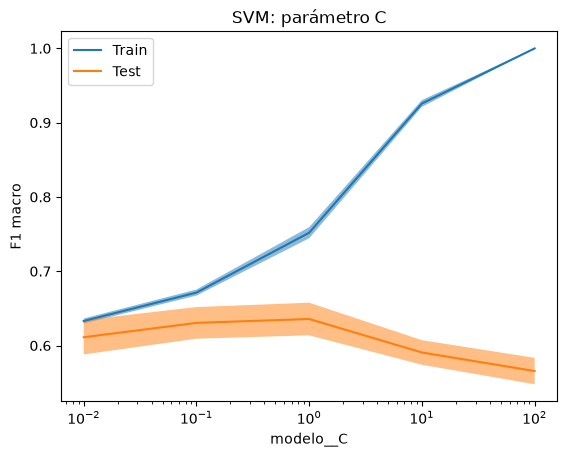

In [10]:

curva_validacion(
    busqueda_svm,
    "modelo__C",
    [0.01, 0.1, 1, 10, 100],
    "SVM: parámetro C"
)


# 4. Validación de modelos

In [ ]:

busquedas = {
    "lda": busqueda_lda,
    "svm": busqueda_svm,
}

comparacion = pd.concat([
    tabla_lda,
    tabla_svm,
])

comparacion[
    [
        "f1_macro_val",
        "f1_macro_val_std",
        "recall_alto_val",
        "recall_alto_val_std",
        "precision_alto_val",
        "diferencia_train_val",
        "mejores_parametros"
    ]
].sort_values(
    "f1_macro_val",
    ascending=False
).round(3).T


modelo,regresion_logistica,lda,svm
f1_macro_val,0.637,0.636,0.636
f1_macro_val_std,0.031,0.028,0.022
recall_alto_val,0.753,0.759,0.726
recall_alto_val_std,0.067,0.052,0.054
precision_alto_val,0.622,0.611,0.636
diferencia_train_val,0.03,0.021,0.116
mejores_parametros,{'modelo__C': 1},"{'modelo__shrinkage': 0.5, 'modelo__solver': '...","{'modelo__C': 1, 'modelo__gamma': 'auto', 'mod..."


# 6. Matrices de confusión

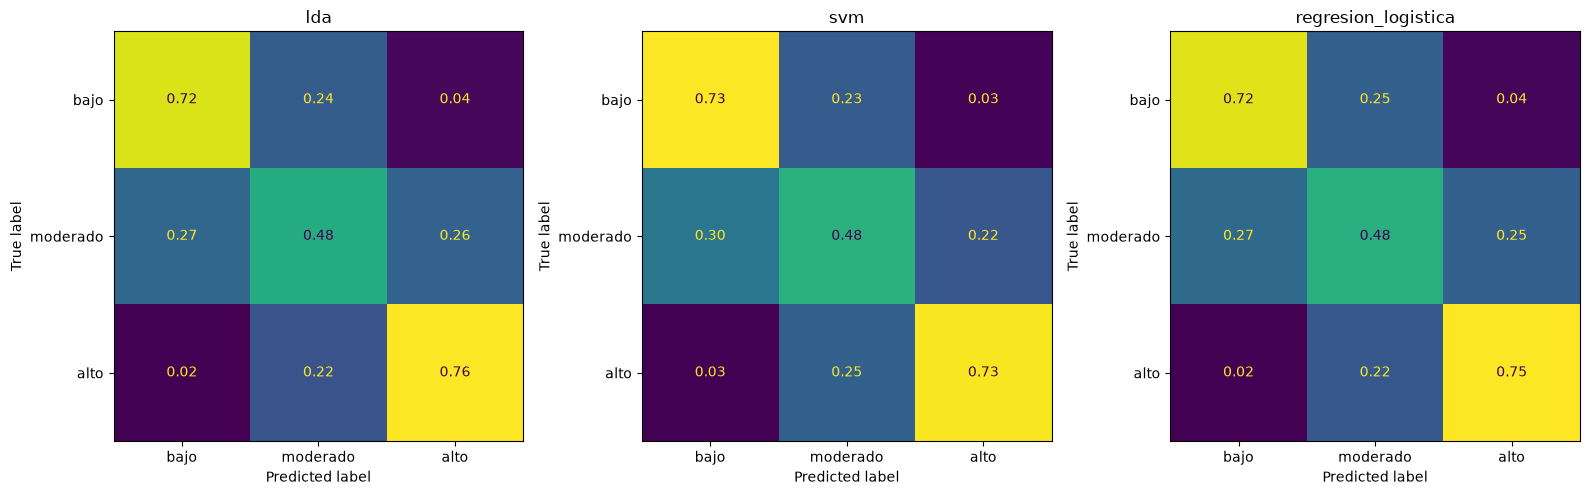

In [16]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (nombre, busqueda) in zip(axes, busquedas.items()):

    y_pred = cross_val_predict(
        busqueda.best_estimator_,
        X_train,
        y_train,
        cv=mod.validador,
        n_jobs=-1
    )

    ConfusionMatrixDisplay.from_predictions(
        y_train,
        y_pred,
        display_labels=["bajo", "moderado", "alto"],
        normalize="true",
        values_format=".2f",
        ax=ax,
        colorbar=False
    )

    ax.set_title(nombre)

plt.tight_layout()
plt.show()


# 7. Comparación folds

In [17]:

folds = pd.DataFrame({
    nombre: pd.read_csv(
        mod.RUTA_RESULTADOS / f"{nombre}_folds.csv",
        index_col=0
    )["f1_macro"]
    for nombre in busquedas
})

folds.round(3)


,lda,svm,regresion_logistica
fold,,,
0,0.657,0.668,0.660
1,0.669,0.638,0.641
2,0.599,0.609,0.608
3,0.650,0.649,0.679
4,0.607,0.615,0.596
